<a href="https://colab.research.google.com/github/silvatria/PCVK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1

# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


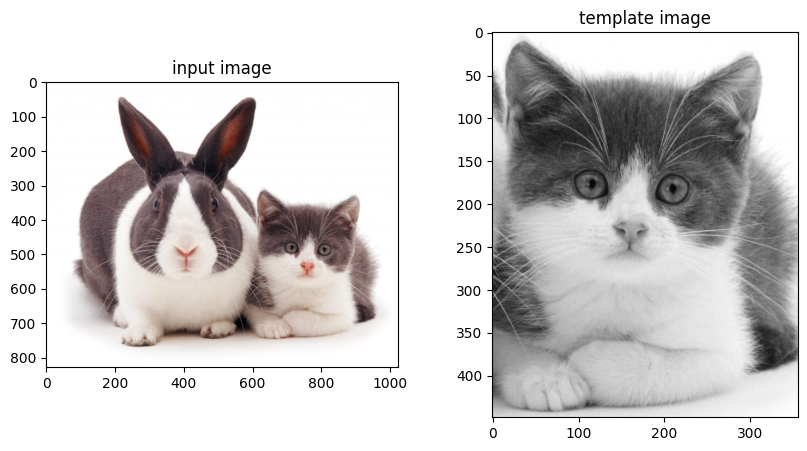

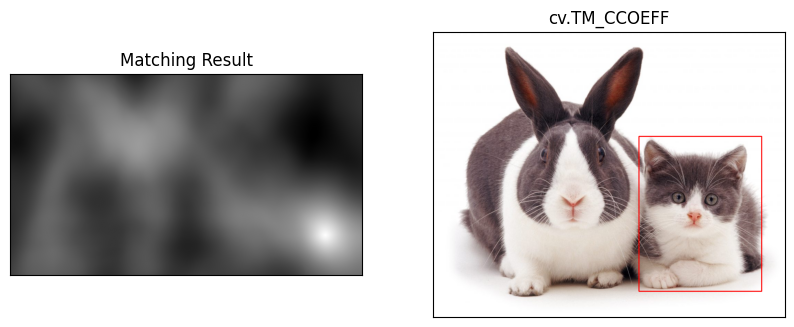

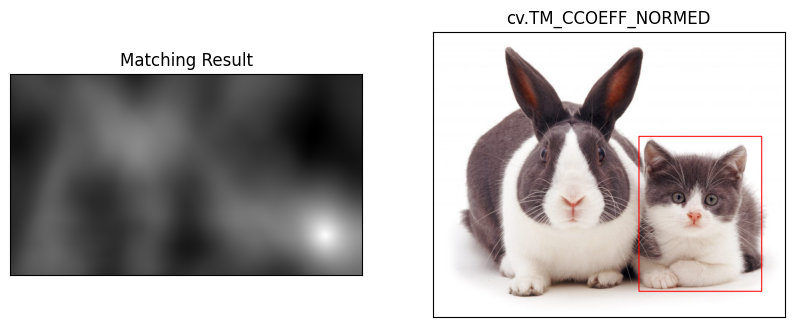

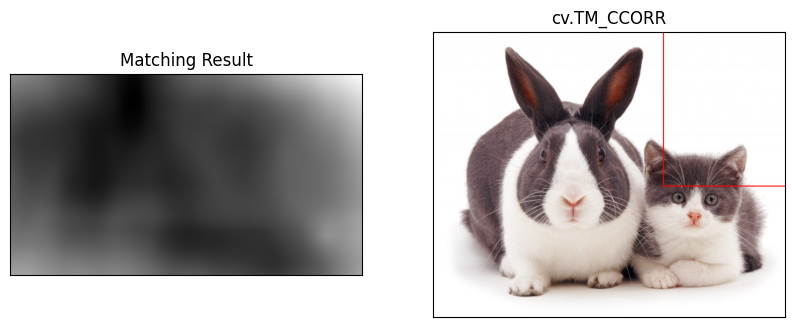

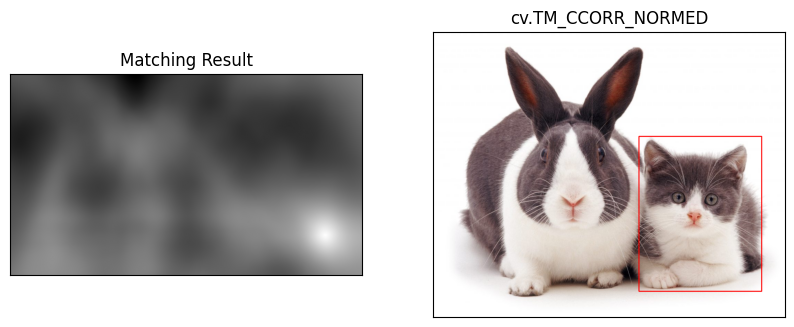

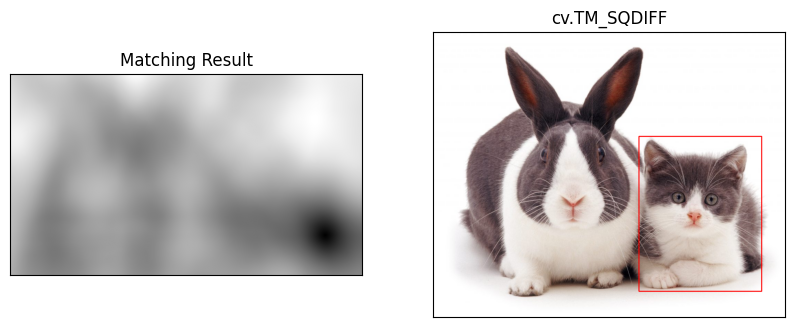

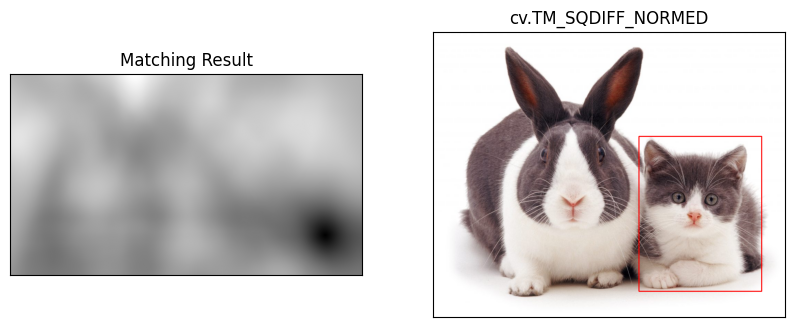

In [26]:
# 2

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Load gambar input dan template
img_rgb = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/cat2_template.jpg', 0)
w, h = template.shape[::-1]

# 1. Tampilkan gambar input dan template di awal (Dengan garis angka/koordinat piksel)
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.title('input image')  # Sumbu x & y sengaja tidak di-hidden biar angka pikselnya muncul
plt.subplot(122), plt.imshow(template, cmap='gray')
plt.title('template image')
plt.show()

# 2. 6 Metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    # Buat salinan gambar agar kotak merah tidak menumpuk antar metode
    img_display = img_rgb.copy()
    img = img_gray.copy()
    method = eval(meth)

    # Eksekusi matchTemplate
    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika metodenya SQDIFF, minimum value adalah yang terbaik
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Gambar kotak merah pada hasil deteksi
    cv.rectangle(img_display, top_left, bottom_right, (0, 0, 255), 2)

    # Plot hasil per metode
    plt.figure(figsize=(10, 4))
    plt.subplot(121), plt.imshow(res, cmap='gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(cv.cvtColor(img_display, cv.COLOR_BGR2RGB))
    plt.title(meth), plt.xticks([]), plt.yticks([])
    plt.show()

Total pulau 'C' yang terdeteksi: 1


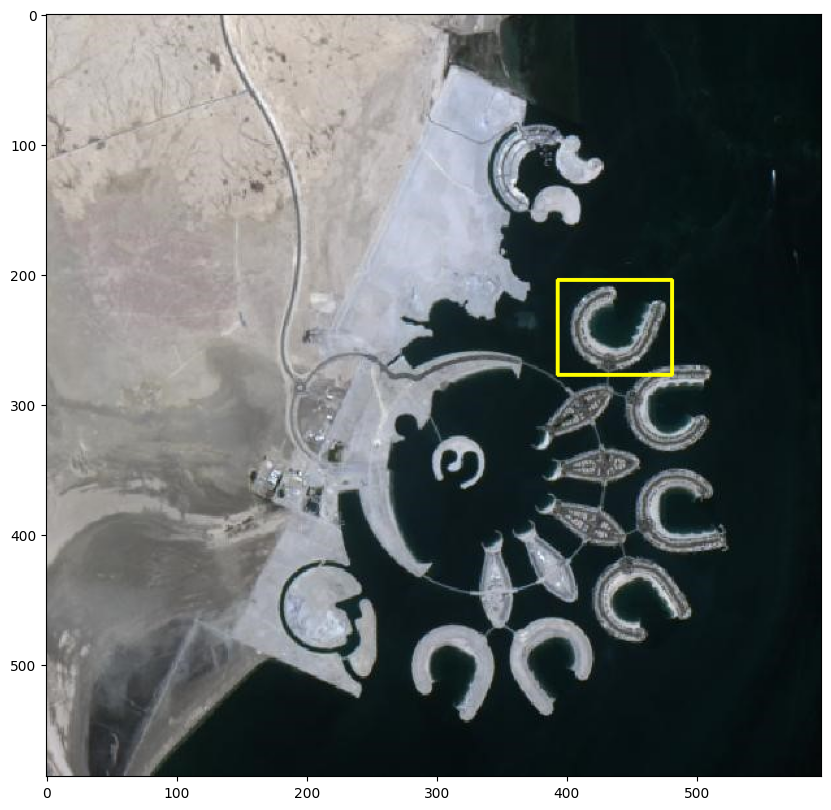

In [25]:
# 3

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load gambar dan template
img_rgb = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/bahrain-template.jpg', 0)
w, h = template.shape[::-1]

# 2. Template Matching
res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)

# Turunin threshold jadi 0.65 biar pulau dengan sudut miring tetap masuk
threshold = 0.65
loc = np.where(res >= threshold)

# 3. Urutkan berdasarkan tingkat kecocokan tertinggi, lalu filter jarak biar gak numpuk
# Ambil koordinat dan skor
matches = []
for pt in zip(*loc[::-1]):
    score = res[pt[1], pt[0]]
    matches.append((pt[0], pt[1], score))

# Urutkan dari skor tertinggi ke terendah
matches = sorted(matches, key=lambda x: x[2], reverse=True)

# Saring titik yang terlalu dekat (Non-Maximum Suppression manual yang lebih longgar)
filtered_pts = []
min_dist = 30  # Jarak minimal piksel antar kotak agar tidak menumpuk di objek yang sama

for pt in matches:
    x, y, score = pt
    # Cek apakah sudah ada titik lain yang terlalu dekat
    keep = True
    for fx, fy, _ in filtered_pts:
        if abs(x - fx) < min_dist and abs(y - fy) < min_dist:
            keep = False
            break
    if keep:
        filtered_pts.append(pt)

# 4. Gambar kotak untuk semua titik yang lolos filter
for pt in filtered_pts:
    cv.rectangle(img_rgb, (pt[0], pt[1]), (pt[0] + w, pt[1] + h), (0, 255, 255), 2)

print(f"Total pulau 'C' yang terdeteksi: {len(filtered_pts)}")

# 5. Plot Hasil
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.axis('on')
plt.show()

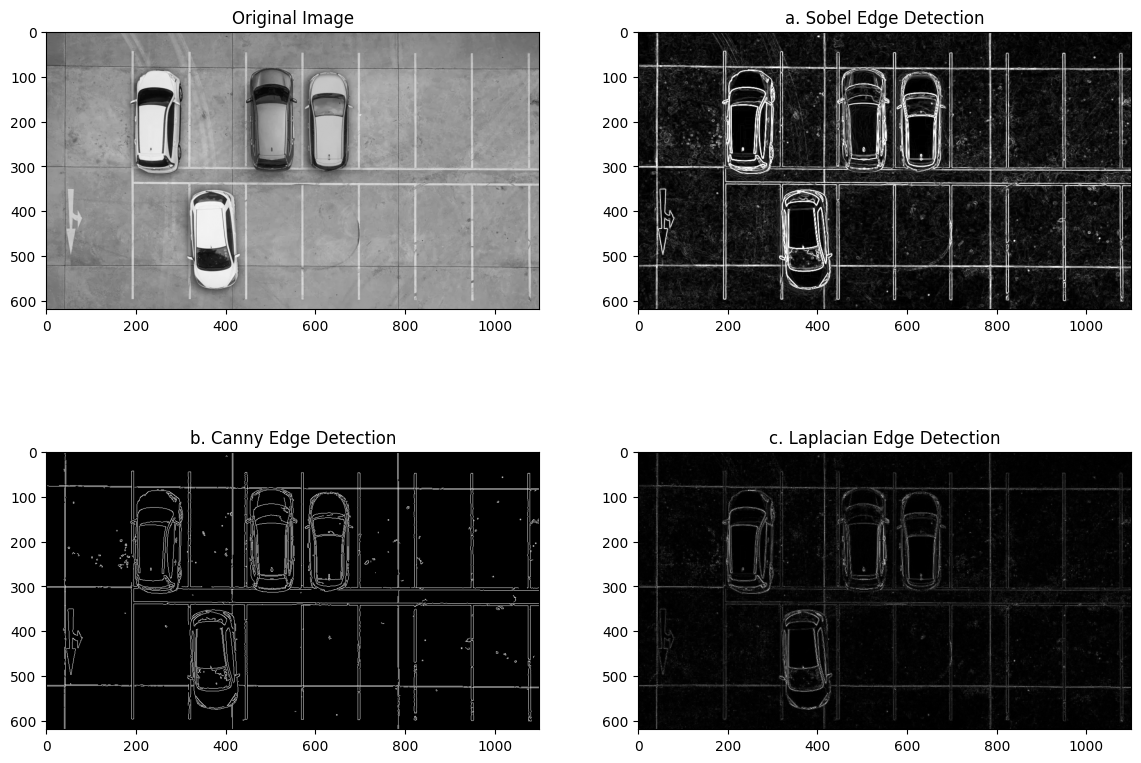

In [24]:
# 4

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load gambar
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/car-park.jpg', 0)

# a. Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)
# Konversi ke uint8 agar tampil kontras hitam-putih
sobel_combined = cv.convertScaleAbs(sobel_combined)

# b. Canny Edge Detection
canny = cv.Canny(img, 100, 200)

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(img, cv.CV_64F)
# Konversi ke uint8 agar nilai negatif jadi positif dan tidak abu-abu kusam
laplacian = cv.convertScaleAbs(laplacian)

# Plotting Hasil
plt.figure(figsize=(14, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(sobel_combined, cmap='gray'), plt.title('a. Sobel Edge Detection')
plt.subplot(223), plt.imshow(canny, cmap='gray'), plt.title('b. Canny Edge Detection')
plt.subplot(224), plt.imshow(laplacian, cmap='gray'), plt.title('c. Laplacian Edge Detection')
plt.show()

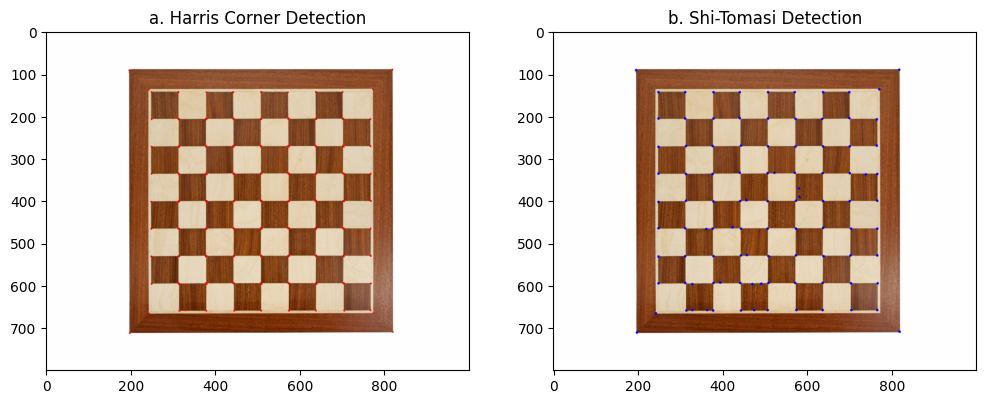

In [23]:
# 5

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load gambar chessboard
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# ==========================================
# a. Harris Corner Detection
# ==========================================
gray_harris = np.float32(gray)
dst = cv.cornerHarris(gray_harris, 2, 3, 0.04)
dst = cv.dilate(dst, None)

img_harris = img.copy()
# Tandai sudut Harris dengan warna merah (0, 0, 255)
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

# ==========================================
# b. Shi-Tomasi Corner Detection
# ==========================================
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
# Ganti np.int0 dengan np.intp agar kompatibel dengan NumPy terbaru
corners = np.intp(corners)

img_shitomasi = img.copy()
for i in corners:
    x, y = i.ravel()
    # Gambar titik sudut Shi-Tomasi dengan lingkaran biru (255, 0, 0)
    cv.circle(img_shitomasi, (x, y), 3, (255, 0, 0), -1)

# ==========================================
# Plotting Hasil (Sesuai Modul)
# ==========================================
plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB))
plt.title('a. Harris Corner Detection')
plt.axis('on')

plt.subplot(122)
plt.imshow(cv.cvtColor(img_shitomasi, cv.COLOR_BGR2RGB))
plt.title('b. Shi-Tomasi Detection')
plt.axis('on')

plt.show()

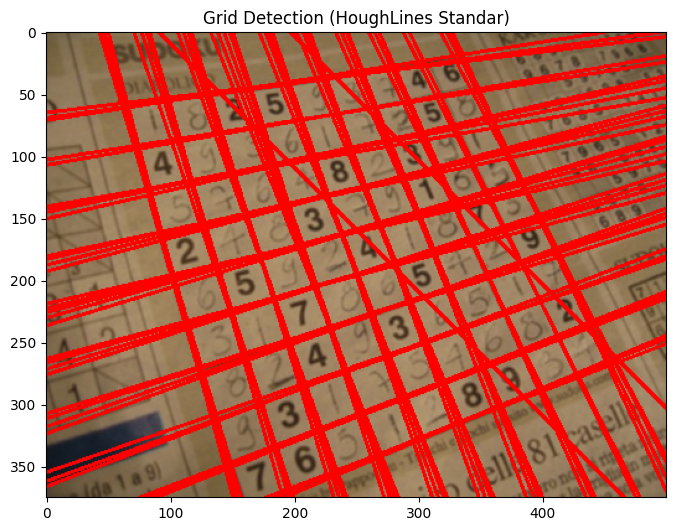

In [22]:
# 6

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load gambar Sudoku
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 2. Canny Edge Detection
blurred = cv.GaussianBlur(gray, (5, 5), 0)
edges = cv.Canny(blurred, 50, 150, apertureSize=3)

# 3. Dilasi dan Erosi tipis untuk menyambungkan garis grid
kernel = np.ones((3,3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

# 4. HoughLines Standar (Threshold dinaikin jadi 180 biar tidak terlalu menumpuk)
lines = cv.HoughLines(eroded, 1, np.pi/180, 180)

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho

        # Konversi koordinat polar ke titik garis lurus melintasi gambar
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))

        cv.line(img, (x1, y1), (x2, y2), (0, 0, 255), 2)

# 5. Plot Hasil
plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Grid Detection (HoughLines Standar)')
plt.axis('on')
plt.show()

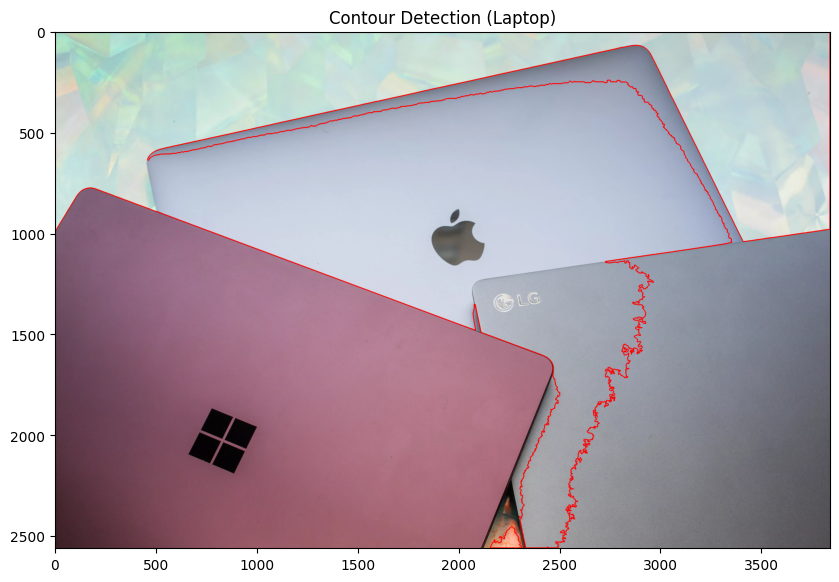

In [21]:
# 7
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load gambar
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/Object Detection/laptop.jpg')

# 2. Konversi ke Grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 3. Gaussian Blur untuk meredam noise dan tekstur background yang mengganggu
blurred = cv.GaussianBlur(gray, (5, 5), 0)

# 4. Otsu Thresholding (otomatis mencari threshold terbaik tanpa angka manual 127)
_, thresh = cv.threshold(blurred, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 5. (Opsional) Morphological Closing untuk menutup lubang kecil/noise di dalam objek
kernel = np.ones((5, 5), np.uint8)
thresh = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel)

# 6. Cari kontur dengan metode RETR_EXTERNAL (hanya mengambil garis luar/paling luar saja)
contours, hierarchy = cv.findContours(thresh, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# 7. Filter kontur berdasarkan luas (area) minimal biar noise kecil-kecil otomatis terabaikan
min_area = 5000  # Sesuaikan jika garis laptopnya ikut terhapus
filtered_contours = [cnt for cnt in contours if cv.contourArea(cnt) > min_area]

# Gambar kontur ke citra asli (ketebalan garis 3 biar jelas)
cv.drawContours(img, filtered_contours, -1, (0, 0, 255), 3)

# 8. Plot Hasil
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Contour Detection (Laptop)')
plt.axis('on')
plt.show()

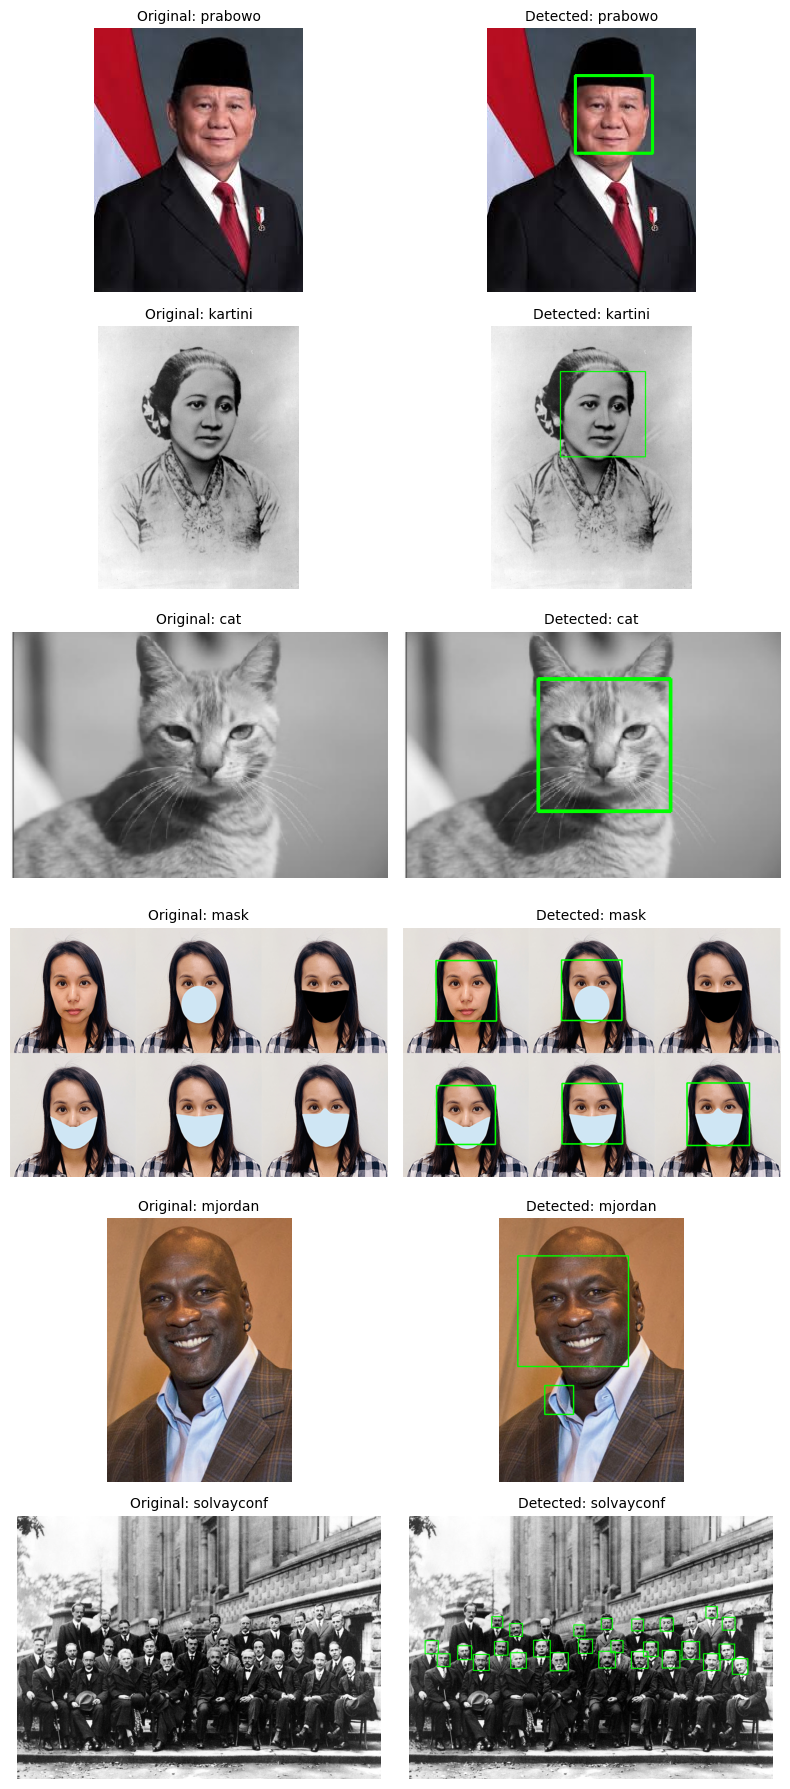

In [20]:
# 8

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Pastikan file XML Haar Cascade ada di direktori kerja (download otomatis jika belum ada)
face_xml = 'haarcascade_frontalface_default.xml'
cat_xml = 'haarcascade_frontalcatface.xml'

if not os.path.exists(face_xml):
    print("Mengunduh haarcascade_frontalface_default.xml...")
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml

if not os.path.exists(cat_xml):
    print("Mengunduh haarcascade_frontalcatface.xml...")
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml

# 2. Load Cascade Classifier dari file lokal
face_cascade = cv.CascadeClassifier(face_xml)
cat_cascade = cv.CascadeClassifier(cat_xml)

filenames = ['prabowo', 'kartini', 'cat', 'mask', 'mjordan', 'solvayconf']

plt.figure(figsize=(8, 3 * len(filenames)))

for i, name in enumerate(filenames):
    # Ekstensi png khusus untuk mask, selain itu jpg
    ext = 'png' if name == 'mask' else 'jpg'
    path = f'/content/drive/MyDrive/2C/PCVK/Images/facedet/{name}.{ext}'

    img_orig = cv.imread(path)
    if img_orig is None:
        print(f"Warning: File {name}.{ext} tidak ditemukan di path tersebut!")
        continue

    img_detected = img_orig.copy()
    gray = cv.cvtColor(img_orig, cv.COLOR_BGR2GRAY)

    if name == 'cat':
        faces = cat_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
    else:
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

    for (x, y, w, h) in faces:
        cv.rectangle(img_detected, (x, y), (x+w, y+h), (0, 255, 0), 2)

    plt.subplot(len(filenames), 2, 2*i + 1)
    plt.imshow(cv.cvtColor(img_orig, cv.COLOR_BGR2RGB))
    plt.title(f"Original: {name}", fontsize=10)
    plt.axis('off')

    plt.subplot(len(filenames), 2, 2*i + 2)
    plt.imshow(cv.cvtColor(img_detected, cv.COLOR_BGR2RGB))
    plt.title(f"Detected: {name}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

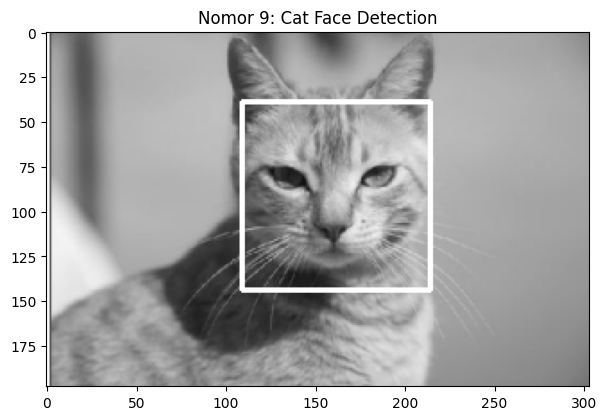

In [19]:
# 9

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Pastikan file XML Haar Cascade ada di direktori kerja (download otomatis jika belum ada)
cat_xml = 'haarcascade_frontalcatface.xml'
if not os.path.exists(cat_xml):
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml

cat_cascade = cv.CascadeClassifier(cat_xml)

# 2. Load gambar kucing langsung dalam mode Grayscale (flag 0)
img_cat = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/facedet/cat.jpg', 0)

if img_cat is None:
    print("Warning: File cat.jpg tidak ditemukan di path tersebut!")
else:
    # 3. Deteksi wajah kucing
    cats = cat_cascade.detectMultiScale(img_cat, scaleFactor=1.03, minNeighbors=3, minSize=(30, 30))

    # Konversi ke BGR/RGB supaya kotaknya bisa berwarna (misal putih atau hijau terang)
    # agar kontras dengan latar belakang grayscale
    img_cat_color = cv.cvtColor(img_cat, cv.COLOR_GRAY2RGB)

    # 4. Gambar rectangle pada wajah kucing yang terdeteksi (Warna Putih sesuai modul)
    for (x, y, w, h) in cats:
        cv.rectangle(img_cat_color, (x, y), (x+w, y+h), (255, 255, 255), 2)

    # 5. Tampilkan hasil dengan ukuran dan format yang pas
    plt.figure(figsize=(7, 7))
    plt.imshow(img_cat_color)
    plt.title('Nomor 9: Cat Face Detection')
    plt.axis('on')  # Menampilkan sumbu koordinat ukuran piksel gambar sesuai referensi
    plt.show()

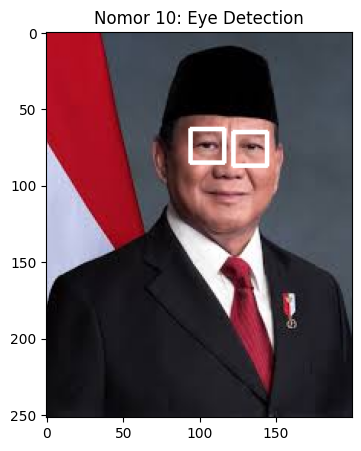

In [18]:
# 10

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os

# 1. Pastikan file XML Haar Cascade ada di direktori lokal (download otomatis jika belum ada)
face_xml = 'haarcascade_frontalface_default.xml'
eye_xml = 'haarcascade_eye.xml'

if not os.path.exists(face_xml):
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml
if not os.path.exists(eye_xml):
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml

# 2. Load cascade wajah dan mata dari file lokal
face_cascade = cv.CascadeClassifier(face_xml)
eye_cascade = cv.CascadeClassifier(eye_xml)

img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/facedet/prabowo.jpg')

if img is None:
    print("Warning: File prabowo.jpg tidak ditemukan di path tersebut!")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Deteksi wajah dengan skala longgar
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
    for (x, y, w, h) in faces:
        roi_gray = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]

        # PARAMETER: scaleFactor=1.05 & minNeighbors=3 supaya lebih sensitif mendeteksi mata
        eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.05, minNeighbors=3)
        for (ex, ey, ew, eh) in eyes:
            cv.rectangle(roi_color, (ex, ey), (ex+ew, ey+eh), (255, 255, 255), 2)

    # Tampilkan hasil dengan ukuran figure proporsional
    plt.figure(figsize=(5, 5), dpi=100)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Nomor 10: Eye Detection')
    plt.axis('on')
    plt.show()

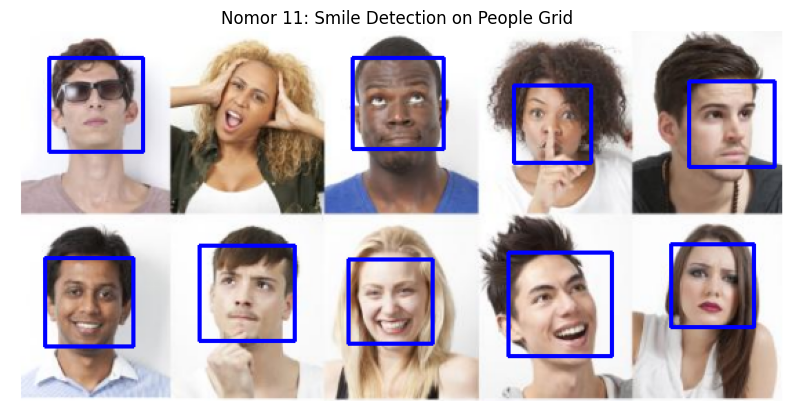

In [17]:
# 11

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Load cascade wajah dan senyuman
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
smile_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

# Load gambar kumpulan orang (ganti 'people.jpg' sesuai nama file aslinya di Drive lu)
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/facedet/people.png')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Deteksi semua wajah dalam kolase
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4)
for (x, y, w, h) in faces:
    # Kotak biru untuk wajah
    cv.rectangle(img, (x, y), (x+w, y+h), (255, 0, 0), 2)

    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]

    # Deteksi senyuman di dalam tiap wajah
    smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=20)
    for (sx, sy, sw, sh) in smiles:
        # Kotak merah untuk senyuman
        cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)

# Tampilkan hasil
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Nomor 11: Smile Detection on People Grid')
plt.axis('off')
plt.show()

<IPython.core.display.Javascript object>

Meminta akses kamera... Pastikan klik 'Allow' di browser, lalu klik tombol 'Capture' di bawah.
Jumlah wajah terdeteksi: 1


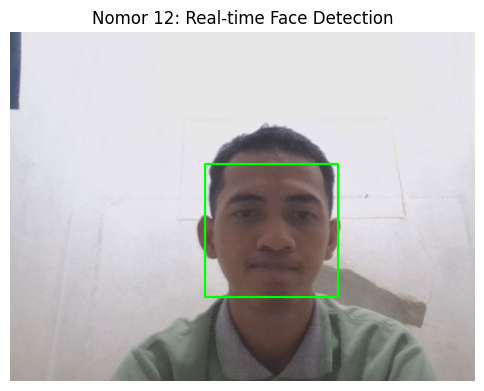

Face detection berhasil dieksekusi!


In [11]:
# 12

import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab.output import eval_js
import IPython.display
from base64 import b64decode
from matplotlib import pyplot as plt

# 1. Injeksi script JavaScript kamera
js_code = IPython.display.Javascript('''
async function takePhoto(quality) {
  const div = document.createElement('div');
  const capture = document.createElement('button');
  capture.textContent = 'Capture';
  div.appendChild(capture);

  const video = document.createElement('video');
  video.style.display = 'block';
  const stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});

  document.body.appendChild(div);
  div.appendChild(video);
  video.srcObject = stream;
  await video.play();

  google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

  await new Promise((resolve) => capture.onclick = resolve);

  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video, 0, 0);
  stream.getVideoTracks()[0].stop();
  div.remove();
  return canvas.toDataURL('image/jpeg', quality);
}
''')

display(js_code)

def take_photo(quality=0.8):
    try:
        data = eval_js('takePhoto({})'.format(quality))
        if not data or not isinstance(data, str) or ',' not in data:
            print("Peringatan: Data dari JavaScript kosong atau format salah.")
            return None

        # Ambil bagian base64 setelah koma
        encoded_data = data.split(',')[1]
        binary = b64decode(encoded_data)
        image = np.frombuffer(binary, dtype=np.uint8)

        if image.size == 0:
            return None

        return cv.imdecode(image, flags=1)
    except Exception as e:
        print(f"Error saat decode gambar: {e}")
        return None

# 2. Eksekusi ambil foto & Face Detection
try:
    print("Meminta akses kamera... Pastikan klik 'Allow' di browser, lalu klik tombol 'Capture' di bawah.")
    img = take_photo()

    if img is None:
        print("Gagal mengambil gambar. Pastikan izin kamera di browser sudah di-allow dan tombol Capture diklik dengan benar.")
    else:
        face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5)
        print(f"Jumlah wajah terdeteksi: {len(faces)}")

        for (x, y, w, h) in faces:
            cv.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

        # Tampilkan pakai matplotlib biar kotaknya dijamin muncul (karena cv2_imshow sering glitch di Colab baru)
        plt.figure(figsize=(6, 6))
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title('Nomor 12: Real-time Face Detection')
        plt.axis('off')
        plt.show()

        print("Face detection berhasil dieksekusi!")

except Exception as err:
    print(f"Gagal total: {err}")

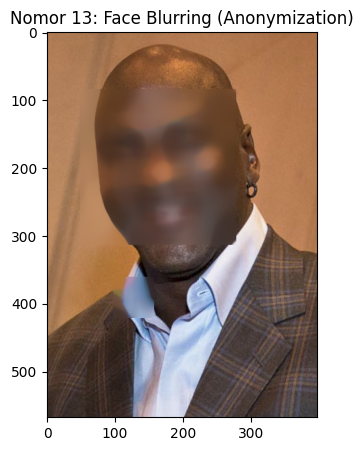

In [12]:
# 13

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os

# 1. Pastikan file XML Haar Cascade ada di direktori kerja
face_xml = 'haarcascade_frontalface_default.xml'
if not os.path.exists(face_xml):
    !wget -q https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml

# Load cascade detector wajah
face_cascade = cv.CascadeClassifier(face_xml)

# 2. Load gambar (mjordan.jpg)
img = cv.imread('/content/drive/MyDrive/2C/PCVK/Images/facedet/mjordan.jpg')

if img is None:
    print("Warning: File mjordan.jpg tidak ditemukan di path tersebut!")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # 3. Deteksi wajah (menggunakan minNeighbors=7 agar tidak salah deteksi ke kerah baju)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=7)

    for (x, y, w, h) in faces:
        # Ambil Region of Interest (ROI) pada area wajah
        face_roi = img[y:y+h, x:x+w]

        # Lakukan blurring menggunakan cv.medianBlur (kernel ganjil 35)
        blurred_face = cv.medianBlur(face_roi, 35)

        # Timpa kembali area wajah di gambar asli dengan hasil yang sudah di-blur
        img[y:y+h, x:x+w] = blurred_face

    # 4. Tampilkan hasil akhir dengan ukuran figure proporsional
    plt.figure(figsize=(5, 5), dpi=100)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Nomor 13: Face Blurring (Anonymization)')
    plt.axis('on')
    plt.show()

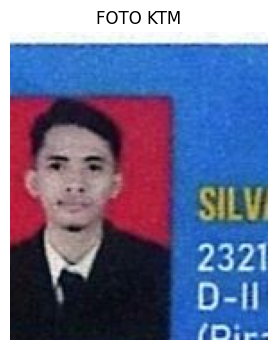

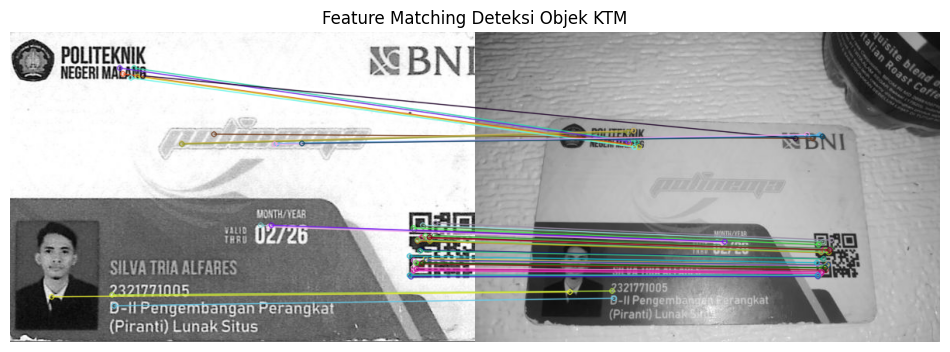

In [34]:
# 14

import cv2 as cv
import numpy as np
import os
from matplotlib import pyplot as plt

# Tentukan path file di Google Drive (sesuaikan kalau nama filenya beda)
path_template = '/content/drive/MyDrive/2C/PCVK/Images/254107023001/template.jpg'
path_target = '/content/drive/MyDrive/2C/PCVK/Images/254107023001/target.jpg'

# Cek apakah file benar-benar ada di direktori
if not os.path.exists(path_template):
    print(f"ERROR: File template tidak ditemukan di: {path_template}")
if not os.path.exists(path_target):
    print(f"ERROR: File target (scene) tidak ditemukan di: {path_target}")

# 1. Load gambar utama KTM (untuk Poin b)
img_ktm = cv.imread(path_template)

if img_ktm is not None:
    img_rgb = cv.cvtColor(img_ktm, cv.COLOR_BGR2RGB)

    # --- POIN B: CROP FOTO KTM ---
    h, w, _ = img_ktm.shape
    y_min, y_max = int(h * 0.52), int(h * 0.95)
    x_min, x_max = int(w * 0.04), int(w * 0.28)

    foto_crop = img_rgb[y_min:y_max, x_min:x_max]

    plt.figure(figsize=(4, 4))
    plt.imshow(foto_crop)
    plt.title('FOTO KTM')
    plt.axis('off')
    plt.show()
else:
    print("Gagal memuat gambar KTM untuk cropping.")

# --- POIN C: FEATURE MATCHING KARTU KTM DENGAN BARANG LAIN ---
template = cv.imread(path_template, cv.IMREAD_GRAYSCALE)
target = cv.imread(path_target, cv.IMREAD_GRAYSCALE)

if template is not None and target is not None:
    # Inisialisasi ORB detector
    orb = cv.ORB_create(nfeatures=1000)

    kp1, des1 = orb.detectAndCompute(template, None)
    kp2, des2 = orb.detectAndCompute(target, None)

    # Brute-Force Matcher dengan NORM_HAMMING
    bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
    matches = bf.match(des1, des2)

    # Urutkan berdasarkan jarak terbaik (similarity)
    matches = sorted(matches, key=lambda x: x.distance)

    # Gambar 50 kecocokan titik terbaik
    result_img = cv.drawMatches(template, kp1, target, kp2, matches[:50], None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    plt.figure(figsize=(12, 6))
    plt.imshow(result_img, cmap='gray')
    plt.title('Feature Matching Deteksi Objek KTM')
    plt.axis('off')
    plt.show()
else:
    print("Gagal menjalankan Feature Matching karena gambar template atau target kosong.")

In [44]:
# D3. Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN

import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

# Sesuaikan path direktori dataset training lu di Google Drive
DATADIR = "/content/drive/MyDrive/2C/PCVK/dataset/training" # subfolder per karakter: 0..9
width, height = 100, 100

if not os.path.exists(DATADIR):
    print(f"Direktori {DATADIR} tidak ditemukan! Buat foldernya dulu ya di Google Drive.")
else:
    # Ambil daftar kelas (hanya berupa folder)
    dirs = sorted([d for d in os.listdir(DATADIR) if os.path.isdir(os.path.join(DATADIR, d))])
    training_data = []

    for char_name in dirs:
        path = os.path.join(DATADIR, char_name)
        class_number = dirs.index(char_name)

        for img in tqdm(os.listdir(path), desc=f"Kelas {char_name}"):
            try:
                img_path = os.path.join(path, img)
                img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img_array is not None:
                    new_array = cv2.resize(img_array, (width, height))
                    training_data.append([new_array, class_number])
            except Exception:
                pass

    if len(training_data) == 0:
        print("\n[PERINGATAN] Data training kosong! Pastikan subfolder 0-9 sudah diisi gambar.")
    else:
        random.shuffle(training_data)
        X, Y = [], []
        for feature, label in training_data:
            X.append(feature)
            Y.append(label)

        X = np.array(X).reshape(-1, width, height, 1)
        Y = np.array(Y)

        # Simpan ke file pickle
        pickle.dump(X, open("X.pickle", "wb"))
        pickle.dump(Y, open("Y.pickle", "wb"))
        pickle.dump(dirs, open("kelas.pickle", "wb"))

        print("\nPreprocessing Selesai!")
        print("jumlah data :", len(training_data))
        print("jumlah kelas:", len(dirs), dirs)

Kelas 9: 100%|██████████| 1/1 [00:00<00:00, 235.61it/s]


Preprocessing Selesai!
jumlah data : 10
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [47]:
import pickle
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D,
 Flatten, Dense, ZeroPadding2D)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))
Y = to_categorical(Y)
X = X / 255.0

width, height = 100, 100
jumlah_kelas = Y.shape[1] # diambil dari data, tidak ditulis tetap

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
 loss='categorical_crossentropy',
 metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1250 - loss: 2.3050

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.1250 - loss: 2.3050 - val_accuracy: 0.0000e+00 - val_loss: 2.3155
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.5000 - loss: 2.2879 - val_accuracy: 0.0000e+00 - val_loss: 2.3342
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.5000 - loss: 2.2722 - val_accuracy: 0.0000e+00 - val_loss: 2.3447
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5000 - loss: 2.2562 - val_accuracy: 0.0000e+00 - val_loss: 2.3552
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.5000 - loss: 2.2385 - val_accuracy: 0.0000e+00 - val_loss: 2.3706
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.5000 - loss: 2.2191 - val_accuracy: 0.0000e+00 - val_loss: 2.3938
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.5000 - loss: 2.1960 - val_accuracy: 0.0000e+00 - val_loss: 2.4206
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.5000 - loss: 2.1720 - val_accuracy: 0.00

In [54]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/2C/PCVK/dataset/testing"
width, height = 100, 100

print("Memeriksa file model dan direktori testing...")

if not os.path.exists("anpr.keras") or not os.path.exists("kelas.pickle"):
    print("[ERROR] File model 'anpr.keras' atau 'kelas.pickle' tidak ditemukan di direktori lokal Colab!")
elif not os.path.exists(data_dir_testing):
    print(f"[ERROR] Direktori testing {data_dir_testing} tidak ditemukan di Google Drive!")
else:
    model = tf.keras.models.load_model("anpr.keras")
    dirs = pickle.load(open("kelas.pickle", "rb"))
    print(f"Model berhasil dimuat. Mengakses folder: {data_dir_testing}\n")

    subfolders = [d for d in os.listdir(data_dir_testing) if os.path.isdir(os.path.join(data_dir_testing, d))]

    if len(subfolders) == 0:
        print("[PERINGATAN] Tidak ada subfolder sampel (misal: mhs_01) di dalam folder testing!")
    else:
        for car in sorted(subfolders):
            folder = os.path.join(data_dir_testing, car)
            temp = ""

            # Ambil semua file gambar di dalam folder sampel
            img_files = sorted([f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

            if len(img_files) == 0:
                print(f"-> Folder '{car}' kosong atau tidak berisi file gambar (.png/.jpg).")
                continue

            for char_img in img_files:
                img_path = os.path.join(folder, char_img)
                img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                if img_array is not None:
                    new_array = cv2.resize(img_array, (width, height))
                    new_array = new_array.reshape(-1, width, height, 1) / 255.0
                    prediction = model.predict(new_array, verbose=0)
                    temp += str(dirs[np.argmax(prediction[0])])

            print("folder name: {} --> Hasil Prediksi No: {}".format(car, temp))

    print("\nProses testing selesai!")


    # ktm test :
    # * 2321771005 (1)
    # * 2341720015 (2)

Memeriksa file model dan direktori testing...
Model berhasil dimuat. Mengakses folder: /content/drive/MyDrive/2C/PCVK/dataset/testing

folder name: ktm_01 --> Hasil Prediksi No: 7537177100
folder name: ktm_02 --> Hasil Prediksi No: 7539177100

Proses testing selesai!
